In [1]:
import pandas as pd

from email_outreach.experiment_utils.metric_loader import load_experiment_metrics
from email_outreach.sae_based_mab.metrics import calculate_recall_precision_at_quantiles, calculate_auc
from email_outreach.utils.constants import ROOT_FOLDER
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def get_precisions_recalls(path: Path, quantiles=1 - np.linspace(start=0, stop=1, num=100)):
    experiments: list[list] = load_experiment_metrics(path)
    recalls: list[float] = []
    precisions: list[float] = []
    for experiment in experiments:
        recall, precision = calculate_recall_precision_at_quantiles(experiment,
                                                                                            quantiles=quantiles)[1:3]

        recalls.append(recall)
        precisions.append(precision)

    return recalls, precisions

In [3]:
def get_recalls_auc(path: Path):
    experiments: list[list] = load_experiment_metrics(path)
    recalls_auc: list[float] = []
    for experiment in experiments:
        recall_auc = calculate_auc(experiment)
        recalls_auc.append(recall_auc)

    return recalls_auc

In [4]:
def delta_pct(lhs: np.ndarray, rhs: np.ndarray, decimals: int = 2 ) -> np.ndarray:
    return ((lhs-rhs)*100).round(decimals)

In [19]:
baseline_path: Path = ROOT_FOLDER / "experiments" / "test_set" / "1" / "contextual_bandit" / "test_legacy"
non_legacy_path: Path = ROOT_FOLDER / "experiments" / "test_set" / "1" / "contextual_bandit" / "test_non_legacy"

In [20]:
baseline_recalls, baseline_precisions = get_precisions_recalls(baseline_path)
non_legacy_recalls, non_legacy_precisions = get_precisions_recalls(non_legacy_path)

In [21]:
baseline_recalls_auc = get_recalls_auc(baseline_path)
non_legacy_recalls_auc = get_recalls_auc(non_legacy_path)

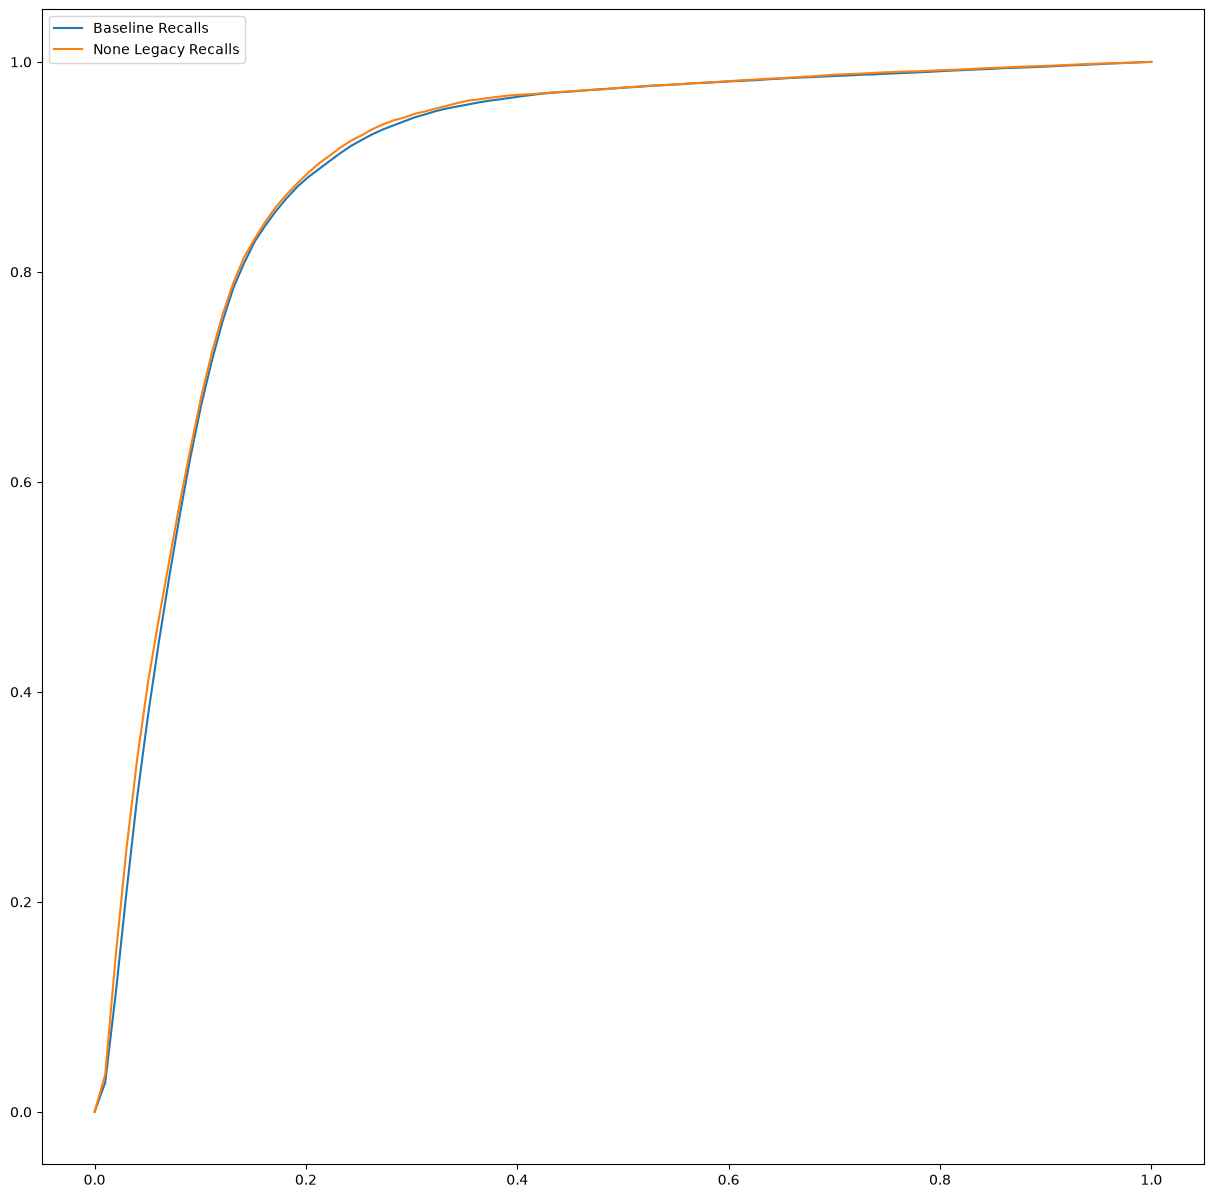

In [24]:
plt.figure(figsize=(15, 15))

plt.plot(np.linspace(start=0, stop=1, num=100), np.array(baseline_recalls).mean(axis=0),
         label="Baseline Recalls")
plt.plot(np.linspace(start=0, stop=1, num=100), np.array(non_legacy_recalls).mean(axis=0),
         label="None Legacy Recalls")

plt.legend()

In [23]:
np.mean(baseline_recalls_auc), np.mean(non_legacy_recalls_auc)

(np.float64(0.8951931796601112), np.float64(0.8989117996006595))

In [28]:
np.array(baseline_recalls).std(axis=0)[[5-1,15-1,25-1,35-1]], np.array(non_legacy_recalls).std(axis=0)[[5-1,15-1,25-1,35-1]]

(array([0.05689751, 0.02466948, 0.01540904, 0.01035494]),
 array([0.02004913, 0.01725057, 0.01261613, 0.01024946]))

In [29]:
np.array(baseline_recalls).mean(axis=0)[[5-1,15-1,25-1,35-1]], np.array(non_legacy_recalls).mean(axis=0)[[5-1,15-1,25-1,35-1]]

(array([0.30047238, 0.80818467, 0.91983595, 0.95757513]),
 array([0.33670751, 0.81375232, 0.92485335, 0.96082888]))

In [30]:
np.array(baseline_recalls).mean(axis=0)[[25-1,50-1, 75-1]], np.array(non_legacy_recalls).mean(axis=0)[[25-1,50-1, 75-1]]

(array([0.91983595, 0.9750184 , 0.9886022 ]),
 array([0.92485335, 0.9750971 , 0.99002483]))

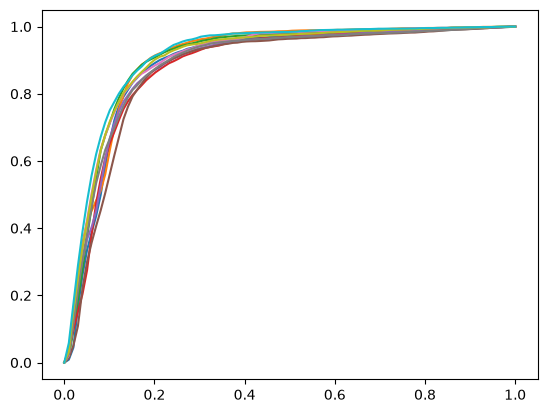

In [27]:

for i in range(len(np.array(baseline_recalls))):
    plt.plot(np.linspace(0,1,100), np.array(baseline_recalls)[i])

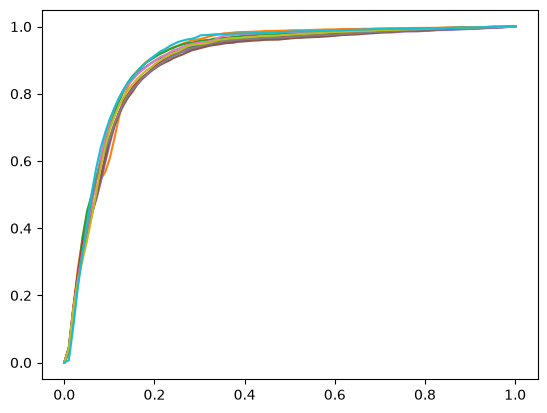

In [26]:

for i in range(len(np.array(non_legacy_recalls))):
    plt.plot(np.linspace(0,1,100), np.array(non_legacy_recalls)[i])